# Robust holograms: designing for the aberrations a trap array will meet, and the pointing error that resists

**Question:** Can a hologram be made robust to the residual aberrations it will meet in the optical system, and does the same design also make it robust to pointing errors of the traps?

- Level: 4, beyond the state of the art (claim BS-4).
- Prerequisites: `06-device-and-aberrations/02-zernike-correction`, which removes the large aberration and leaves a residual, and `03-gerchberg-saxton/03-phase-fixed-wgs-against-slmsuite` for M07.
- Reading time: about 30 minutes. The notebook runs in about two minutes.

## Objectives

The previous notebook corrects the aberration of the system as well as the camera can measure it. What is left is a residual that nobody knows exactly: it changes with temperature, with the alignment of the day, with the position in the field. A hologram that is perfect for the ideal system, as phase-fixed weighted GS is, may be fragile to that residual, and the usual remedy is to correct again or to correct each site. B4 takes a different route and designs the hologram for the distribution of residuals instead of for one. By the end you can:

- state the expected cost that B4 minimises, and say what a sigma-point design replaces;
- measure how fragile a nominal hologram is, by the mean and the 95th percentile of the spread over an ensemble of residuals;
- compare B4 with the nominal methods on the same draws, with an interval and a paired count;
- test the claim on a residual wider than the one the design assumed;
- read the measured negative on pointing errors, and say why it is reported.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b4_robust
from pipeline.model.holo.methods.beyond.b4_robust import ensemble_stats

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook uses the layout of case C09 of `data/examples/cases.json`: 16 traps on a 256 x 256 pixel SLM. The large aberration that the case carries is the one the previous notebook removes; here the object is what remains after it.

- Owner: this repository; the case is synthetic, and the residual distribution is a stated model of this unit, not a measurement.
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C09.

In [2]:
# case C09 supplies the layout: 16 traps; its own large aberration is what the previous notebook removed
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C09"]
setup = build.setup_of(rec)
target = build.target_of(rec)
traps = target.traps
print(rec["case_id"], "|", len(traps), "traps | SLM", setup.n_pix, "x", setup.n_pix, "pixels")

C09_aberrated | 16 traps | SLM 256 x 256 pixels


## Method

### The residual, and the expected cost

The residual is modelled as Zernike coefficients (Noll, 1976) in modes 4 to 11, each independent and normal with zero mean and a standard deviation of $s_a = 0.02$ waves, so its rms is $0.02 \sqrt{8} = 0.057$ waves and its Maréchal Strehl ratio is about 0.88. The value of $s_a$ is a choice of this unit: it is stated, not sourced, and the dossier lists device dependence of such priors as a risk. For a hologram $\phi$ and a residual $a$, with $W(a)$ the wavefront it adds to the phase, B4 minimises the expected loss

$$\min_\phi \; \mathbb{E}_a\, L\big(\phi + 2\pi W(a)\big), \qquad L = \frac{\sum_m (I_m - T_m)^2}{\sum_m T_m^2},$$

where the targets $T_m$ ask for equal traps at 0.9 of the efficiency $e_0$ of the starting hologram. The expectation is approximated by 16 sigma points, plus and minus $s_a \sqrt 8$ waves on one of the eight modes at a time, which reproduce the mean and the covariance of the distribution exactly and make the loss deterministic, so that conjugate gradient with a line search can minimise it. The gradient is the one of the ideal cost evaluated at the shifted phase, because the aberration is an additive phase.

The measure of fragility is the one of the ensemble: the 95th percentile and the mean, over 100 seeded draws of the residual, of the relative standard deviation of the trap intensities, and the mean efficiency. The notebook uses 100 draws instead of the 200 of the pipeline's test, to stay inside the time limit.

## State of the art

The state of the art for a large array of equal traps is a nominal hologram: phase-fixed weighted GS (M07, Kim et al., 2019) and the weighted loop (M06). Both are computed for the corrected system with 30 iterations, and the cell prints their nominal efficiency and spread, on the ideal system.

In [3]:
# two nominal holograms for the corrected system, 30 iterations each: weighted GS and phase-fixed weighted GS
res06 = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
res07 = m07_phase_fixed_wgs.run(setup, target, budget=Budget(30), rng=Rng(1))
for name, res in (("M06", res06), ("M07", res07)):
    h = res.history[-1]
    print(f"{name}: nominal efficiency {h['efficiency']:.4f}  rel. std {h['rel_std']:.4f} %")

M06: nominal efficiency 0.7956  rel. std 2.9624 %
M07: nominal efficiency 0.7628  rel. std 0.0001 %


M07 is exactly uniform on the ideal system (a relative standard deviation of 0.0001 percent), with an efficiency of 0.7628. M06 has a nominal spread of 2.96 percent and an efficiency of 0.7956. Now the residual arrives: the next cell scores both holograms under 100 seeded draws of 0.02 waves rms on each of modes 4 to 11.

In [4]:
# the same holograms under 100 draws of residual aberration: 0.02 waves rms on each of Noll modes 4 to 11
stats06 = ensemble_stats(setup, res06.phi, traps, n=100)
stats07 = ensemble_stats(setup, res07.phi, traps, n=100)
for name, s in (("M06", stats06), ("M07", stats07)):
    print(f"{name}: mean efficiency {s['efficiency_mean']:.4f}  mean rel. std "
          f"{s['sigma_mean']:.2f} %  95th percentile {s['sigma_p95']:.2f} %")

M06: mean efficiency 0.7252  mean rel. std 3.50 %  95th percentile 4.54 %
M07: mean efficiency 0.6954  mean rel. std 2.19 %  95th percentile 3.63 %


A residual of only 0.057 waves rms, a Strehl ratio of 0.88, is enough to destroy the nominal perfection. M07, which was uniform to six digits, now has a mean spread of 2.19 percent and a 95th percentile of 3.63 percent, and its mean efficiency falls from 0.7628 to 0.6954, a loss of 9 percent of the light. M06 keeps more light under the residual, 0.7252, but is less uniform, with a mean of 3.50 percent and a 95th percentile of 4.54. The nominal methods are therefore equally fragile to this level of residual, whatever their nominal spread, and the 95th percentile of M07, 3.63 percent, is the number that B4 has to beat. The table does not say that a larger residual would not do worse, or what the spread would be if the traps were corrected site by site.

A fair objection is that the nominal hologram was only given 30 iterations, and that more effort might make it less fragile. The cell gives phase-fixed weighted GS 100 iterations and scores the result under the same 100 draws.

In [5]:
# the nominal baseline given more effort: phase-fixed weighted GS for 100 iterations instead of 30
res07_long = m07_phase_fixed_wgs.run(setup, target, budget=Budget(100), rng=Rng(1))
stats07_long = ensemble_stats(setup, res07_long.phi, traps, n=100)
print(f"M07, 100 iterations: nominal rel. std {res07_long.history[-1]['rel_std']:.1e} %")
print(f"mean efficiency {stats07_long['efficiency_mean']:.4f}  mean rel. std "
      f"{stats07_long['sigma_mean']:.2f} %  95th percentile {stats07_long['sigma_p95']:.2f} %")

M07, 100 iterations: nominal rel. std 4.7e-14 %
mean efficiency 0.6954  mean rel. std 2.19 %  95th percentile 3.63 %


More effort changes nothing: the nominal spread is already at the 5e-14 percent of rounding, and under the draws the mean efficiency is 0.6954, the mean spread 2.19 percent and the 95th percentile 3.63 percent, the same as at 30 iterations. A nominal method can only converge to the nominal optimum, which is exactly uniform and exactly as fragile, so the 3.63 percent is the number to beat and no amount of iterations moves it.

## Beyond the state of the art

### B4: a hologram for the distribution of residuals (BS-4)

The claim of B4 is that optimising the expected cost over the residual gives a hologram whose 95th percentile of spread is at least 1.25 times below that of M07, for a loss of at most 10 percent of the efficiency. The gap it answers is that corrections in the literature are global or per site, and none optimises for a distribution of what remains (arXiv 2512.15967). The cell runs B4 for 40 conjugate-gradient steps from the M07 hologram. It is the longest cell of the notebook, because every step evaluates the cost at 16 shifted phases.

In [6]:
# B4: the expected cost over 16 sigma points of residual aberration, 40 conjugate-gradient steps from the
# M07 hologram
res_b4 = b4_robust.run(setup, target, budget=Budget(40), rng=Rng(1), init=res07.phi)
h = res_b4.history[-1]
print(f"B4: nominal efficiency {h['efficiency']:.4f}  nominal rel. std {h['rel_std']:.4f} %")
print(f"target level of the expected cost: {res_b4.meta['level']:.4f}")

B4: nominal efficiency 0.7538  nominal rel. std 0.2147 %
target level of the expected cost: 0.6865


B4 trades a little of the nominal result for the robustness: on the ideal system its efficiency is 0.7538 and its spread 0.2147 percent, against 0.7628 and 0.0001 for M07; the level of the target it was given is 0.6865, which is 0.9 of the efficiency of M07 on the ideal system. The decisive test is the ensemble. The next cell scores B4 on the same 100 draws as M07 (the generator is seeded, so the draws are paired), and adds two measures that a pair of 95th percentiles does not give: in how many draws B4 is the more uniform of the two, and a paired bootstrap, resampling the draws 1000 times, of the ratio of the two 95th percentiles.

In [7]:
# B4 under the same 100 draws (the same seed, so the draws are paired), and a paired bootstrap of the ratio
# of 95th percentiles
stats_b4 = ensemble_stats(setup, res_b4.phi, traps, n=100)
sig07, sig_b4 = stats07["sigmas"], stats_b4["sigmas"]
print(f"B4: mean efficiency {stats_b4['efficiency_mean']:.4f}  mean rel. std "
      f"{stats_b4['sigma_mean']:.2f} %  95th percentile {stats_b4['sigma_p95']:.2f} %")
print(f"ratio of 95th percentiles M07 / B4: {stats07['sigma_p95'] / stats_b4['sigma_p95']:.2f}")
print(f"efficiency change: {100 * (stats_b4['efficiency_mean'] / stats07['efficiency_mean'] - 1):+.1f} %")
print(f"draws where B4 is more uniform than M07: {int(np.sum(sig_b4 < sig07))} of {len(sig07)}")
draws = np.random.default_rng(11)
ratios = []
for _ in range(1000):
    pick = draws.integers(0, len(sig07), len(sig07))
    ratios.append(np.percentile(sig07[pick], 95) / np.percentile(sig_b4[pick], 95))
print(f"bootstrap 90 % interval of the ratio: {np.percentile(ratios, 5):.2f} {np.percentile(ratios, 95):.2f}")

B4: mean efficiency 0.6875  mean rel. std 0.95 %  95th percentile 2.27 %
ratio of 95th percentiles M07 / B4: 1.60
efficiency change: -1.1 %
draws where B4 is more uniform than M07: 100 of 100
bootstrap 90 % interval of the ratio: 1.35 2.16


The figure sorts the spread of each hologram over the 100 draws, which is the empirical distribution of the spread.

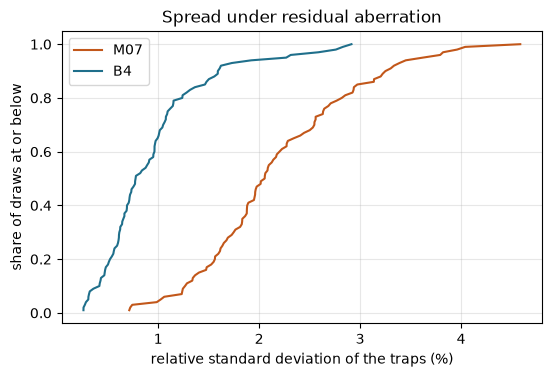

In [8]:
# the spread of the traps over the 100 draws, sorted: M07 against B4
fig, ax = plt.subplots(figsize=(6.2, 3.8))
share = np.arange(1, len(sig07) + 1) / len(sig07)
ax.plot(np.sort(sig07), share, label="M07", color="#c2571a")
ax.plot(np.sort(sig_b4), share, label="B4", color="#1f6f8b")
ax.set_xlabel("relative standard deviation of the traps (%)")
ax.set_ylabel("share of draws at or below")
ax.set_title("Spread under residual aberration")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

B4 has a mean spread of 0.95 percent and a 95th percentile of 2.27 percent against 2.19 and 3.63 for M07: a ratio of 1.60 at the 95th percentile, with a paired bootstrap interval of 1.35 to 2.16 at 90 percent, which excludes the criterion of 1.25 from below. The efficiency changes by -1.1 percent, from 0.6954 to 0.6875, well inside the allowed 10. B4 is more uniform than M07 in all 100 draws, so this is not a few lucky ones: the whole blue curve lies to the left of the orange one. The figure does not tell the generality of the design, because the draws come from the same distribution that the sigma points describe, and a design tested on the distribution it was built for is tested in sample. The cell below changes the distribution.

### A wider residual than the one assumed

The same two holograms are scored on a residual with a standard deviation of 0.03 waves per mode, 1.5 times the value the design assumed, so its rms is 0.085 waves. A hologram designed for a narrower distribution may be worse than a nominal one when reality is wider, or it may keep part of the gain.

In [9]:
# both holograms under a wider residual than B4 was designed for: 0.03 waves per mode (rms 0.085 waves)
wide07 = ensemble_stats(setup, res07.phi, traps, n=100, aberration=0.03)
wide_b4 = ensemble_stats(setup, res_b4.phi, traps, n=100, aberration=0.03)
for name, s in (("M07", wide07), ("B4", wide_b4)):
    print(f"{name}: mean efficiency {s['efficiency_mean']:.4f}  "
          f"95th percentile {s['sigma_p95']:.2f} %")
print(f"ratio of 95th percentiles M07 / B4: {wide07['sigma_p95'] / wide_b4['sigma_p95']:.2f}")

M07: mean efficiency 0.6228  95th percentile 5.67 %
B4: mean efficiency 0.6162  95th percentile 4.98 %
ratio of 95th percentiles M07 / B4: 1.14


B4 keeps a part of the gain and loses most of it: the 95th percentile is 5.67 percent for M07 and 4.98 for B4, a ratio of 1.14, below the criterion of 1.25, and the efficiencies are 0.6228 and 0.6162. The claim of B4 holds for the residual it was designed for and weakens quickly outside it. A user of the method must therefore choose $s_a$ from the instrument, and the notebook offers no source for its value.

### Pointing errors

The dossier proposed that the same expected cost could also cover the pointing errors of the traps, a displacement of each trap from its programmed position. The pipeline carries that option, with a sampled design (Adam over 8 random draws of the aberration and the displacement of every trap), and the claim was narrowed after a first measurement, so the notebook reports it as a measurement. The cell scores three holograms under a pointing error alone, with each trap displaced by 0.15 FFT bins rms (a spot is about two bins wide) and no aberration: M07, B4 designed for aberrations, and a B4 designed with the pointing error.

In [10]:
# pointing error alone: traps displaced 0.15 FFT bins rms; M07, B4 and a B4 designed with pointing noise
res_b4_pointing = b4_robust.run(setup, target, budget=Budget(30), rng=Rng(1), init=res07.phi, pointing_bins=0.15)
holograms = {
    "M07": res07.phi,
    "B4 (aberration)": res_b4.phi,
    "B4 (aberration + pointing)": res_b4_pointing.phi,
}
pointing = {name: ensemble_stats(setup, phi, traps, n=100, aberration=0.0, pointing_bins=0.15)
            for name, phi in holograms.items()}
for name, s in pointing.items():
    print(f"{name:34s} mean efficiency {s['efficiency_mean']:.4f}  "
          f"95th percentile {s['sigma_p95']:.2f} %")
base_p95 = pointing["M07"]["sigma_p95"]
for name, s in pointing.items():
    print(f"{name:34s} ratio to M07 {base_p95 / s['sigma_p95']:.2f}")

M07                                mean efficiency 0.7416  95th percentile 4.55 %
B4 (aberration)                    mean efficiency 0.7328  95th percentile 4.79 %
B4 (aberration + pointing)         mean efficiency 0.7404  95th percentile 4.49 %
M07                                ratio to M07 1.00
B4 (aberration)                    ratio to M07 0.95
B4 (aberration + pointing)         ratio to M07 1.01


The bars compare the 95th percentile of the spread of M07 and of B4 with an aberration only and with a pointing error only.

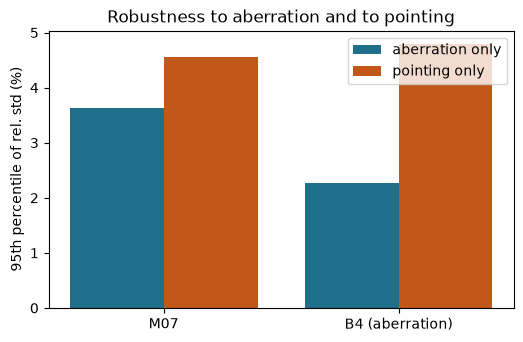

In [11]:
# 95th percentile of the spread, with and without a pointing error, for M07 and for B4
labels = ["M07", "B4 (aberration)"]
p95_aberration = [stats07["sigma_p95"], stats_b4["sigma_p95"]]
p95_pointing = [s["sigma_p95"] for s in list(pointing.values())[:2]]
slots = np.arange(2)
fig, ax = plt.subplots(figsize=(6.0, 3.6))
ax.bar(slots - 0.2, p95_aberration, 0.4, label="aberration only", color="#1f6f8b")
ax.bar(slots + 0.2, p95_pointing, 0.4, label="pointing only", color="#c2571a")
ax.set_xticks(slots)
ax.set_xticklabels(labels)
ax.set_ylabel("95th percentile of rel. std (%)")
ax.set_title("Robustness to aberration and to pointing")
ax.legend()
plt.show()

Under a pointing error alone the three holograms are the same to within 6 percent: the 95th percentile of the spread is 4.55 percent for M07, 4.79 for B4 designed for aberrations (a ratio of 0.95, slightly worse) and 4.49 for B4 designed with pointing noise (1.01). The design that sees the pointing error does not learn from it. The pipeline's own explanation is that a displaced trap loses intensity in proportion to the curvature of its spot, and that curvature is fixed by the width of the spot, which no phase pattern can change without giving up half of the peak efficiency; the notebook did not test that explanation, only the outcome. In the figure the blue bars, with an aberration only, differ by a factor of 1.6 and the orange bars, with a pointing error only, do not differ at all. The claim of BS-4 is therefore stated for aberrations, and the pointing result is a negative that the benchmark also reports.

## Results

**Answer:** A hologram can be made robust to the residual aberrations it will meet, within the width it was designed for, and not to pointing errors. On the 16 traps of case C09, a residual of 0.02 waves rms on each of Noll modes 4 to 11 turns the nominal M07 hologram, exactly uniform on the ideal system, into one with a 95th percentile of the spread of 3.63 percent and an efficiency of 0.6954. B4, which optimises the expected cost over the residual, has a 95th percentile of 2.27 percent: a ratio of 1.60 with a paired 90 percent interval of 1.35 to 2.16, better in all 100 draws, for an efficiency of 0.6875, 1.1 percent lower. The gain does not survive a residual 1.5 times wider (ratio 1.14, 5.67 against 4.98 percent), and it does not extend to pointing: with each trap displaced by 0.15 bins the 95th percentile is 4.55 percent for M07 and 4.49 for a B4 designed with that error, a ratio of 1.01.

What the notebook does not show is the value of $s_a$ for a real instrument, which the unit chose; more than one starting hologram; or a pointing error larger than 0.15 bins.

## Summary

- A nominal hologram, even one exactly uniform on the ideal system, is fragile: a residual of 0.057 waves rms raises its mean spread to 2.19 percent.
- B4 minimises the expected cost over the residual with 16 sigma points and conjugate gradient; its 95th percentile is 1.60 times below M07's for 1.1 percent less light.
- The gain is paired and consistent over the draws, but it is tested on the distribution the design assumed.
- On a residual 1.5 times wider the ratio falls to 1.14, below the 1.25 of the criterion.
- Robustness to pointing errors does not follow from the same design: the ratio is 1.01 with a pointing error alone.

## References

- Machu et al. Full-field-of-view aberration correction for large arrays of focused beams, the nearest prior work. https://arxiv.org/abs/2512.15967
- Kim et al. (2019). Large-scale uniform optical focus array generation with a phase spatial light modulator. Optics Letters 44, 3178. https://doi.org/10.1364/OL.44.003178
- Noll (1976). Zernike polynomials and atmospheric turbulence. Journal of the Optical Society of America 66, 207. https://doi.org/10.1364/JOSA.66.000207